<a href="https://colab.research.google.com/github/RMwiggins718/Convolutional-Neural-Network-CNN-for-MNIST-Handwritten-Digit-Classification/blob/main/Implementing_and_Visualizing_Adversarial_Examples.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Imports and Device Configuration
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms

# Configure device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
# Cell 2: Load MNIST Dataset
batch_size = 64

transform = transforms.Compose(
    [transforms.ToTensor()]
)  # Values scaled between [0, 1]

train_loader = torch.utils.data.DataLoader(
    datasets.MNIST(
        "./data", train=True, download=True, transform=transform
    ),
    batch_size=batch_size,
    shuffle=True,
)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST("./data", train=False, download=True, transform=transform),
    batch_size=batch_size,
    shuffle=False,
)
print("MNIST dataset loaded successfully.")

100%|██████████| 9.91M/9.91M [00:00<00:00, 24.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 582kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.71MB/s]

MNIST dataset loaded successfully.


In [15]:
# Cell 3: Define the Convolutional Neural Network (CNN) - Cleaned
class MNIST_CNN(nn.Module):

  def __init__(self):
    super(MNIST_CNN, self).__init__()
    self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(2, 2)
    self.fc1 = nn.Linear(64 * 7 * 7, 128)
    self.fc2 = nn.Linear(128, 10)

  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))  # Conv1 -> ReLU -> MaxPool
    x = self.pool(F.relu(self.conv2(x)))  # Conv2 -> ReLU -> MaxPool
    x = x.view(-1, 64 * 7 * 7)  # Flatten
    x = F.relu(self.fc1(x))  # Fully connected 1 -> ReLU
    x = self.fc2(x)  # Output layer
    return x


model = MNIST_CNN().to(device)
print(model)

MNIST_CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [14]:
# Cell 4: Define Training and Testing Loops
def train_model(model, device, train_loader, optimizer, epoch):
  model.train()
  for batch_idx, (data, target) in enumerate(train_loader):
    data, target = data.to(device), target.to(device)
    optimizer.zero_grad()
    output = model(data)
    loss = F.cross_entropy(output, target)
    loss.backward()
    optimizer.step()


def test_model(model, device, test_loader):
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for data, target in test_loader:
      data, target = data.to(device), target.to(device)
      output = model(data)
      _, predicted = torch.max(output.data, 1)
      total += target.size(0)
      correct += (predicted == target).sum().item()

  accuracy = 100.0 * correct / total
  return accuracy


# Confirmation print statement to provide output when the cell runs
print("Training and testing loops defined successfully!")

Training and testing loops defined successfully!


In [13]:
# Cell 5: Implement FGSM and PGD Attack Methods
def generate_fgsm_attack(model, images, labels, epsilon):
  images = images.clone().detach().requires_grad_(True)
  outputs = model(images)
  loss = F.cross_entropy(outputs, labels)

  model.zero_grad()
  loss.backward()

  # Collect the element-wise sign of the data gradient
  data_grad = images.grad.data
  perturbed_image = images + epsilon * data_grad.sign()
  perturbed_image = torch.clamp(
      perturbed_image, 0, 1
  )  # Clip to valid pixel range
  return perturbed_image


def generate_pgd_attack(
    model, images, labels, epsilon=0.3, alpha=0.01, num_iter=40
):
  perturbed_image = images.clone().detach() + torch.FloatTensor(
      images.shape
  ).uniform_(-epsilon, epsilon).to(device)
  perturbed_image = torch.clamp(perturbed_image, 0, 1).detach()

  for _ in range(num_iter):
    perturbed_image.requires_grad = True
    outputs = model(perturbed_image)
    loss = F.cross_entropy(outputs, labels)

    model.zero_grad()
    loss.backward()

    data_grad = perturbed_image.grad.data
    perturbed_image = (
        perturbed_image + alpha * data_grad.sign()
    )  # Step towards loss maximization

    # Projection step to keep within epsilon ball and [0,1] range
    eta = torch.clamp(perturbed_image - images, min=-epsilon, max=epsilon)
    perturbed_image = torch.clamp(images + eta, min=0.0, max=1.0).detach()

  return perturbed_image


# Confirmation print statement so you see an output when running this cell
print("FGSM and PGD attack functions defined successfully!")

FGSM and PGD attack functions defined successfully!


Starting baseline model training...
Epoch 1: Train Loss = 0.0285 | Test Accuracy = 98.83%
Epoch 2: Train Loss = 0.0203 | Test Accuracy = 99.05%
Epoch 3: Train Loss = 0.0137 | Test Accuracy = 99.04%


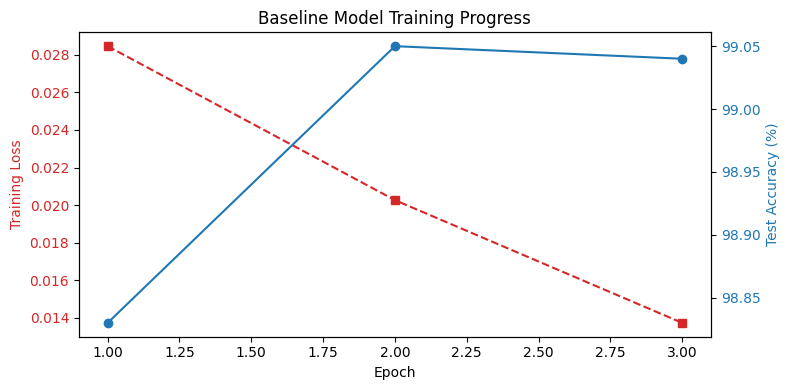

In [12]:
# Cell 6: Execute Training Routine with Epoch Visualizations (Updated)
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 3

train_losses = []
test_accuracies = []

print("Starting baseline model training...")
for epoch in range(1, epochs + 1):
  # Train and collect loss
  model.train()
  running_loss = 0.0
  for batch_idx, (data, target) in enumerate(train_loader):
    data, target = data.to(device), target.to(device)
    optimizer.zero_grad()
    output = model(data)
    loss = F.cross_entropy(output, target)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

  avg_train_loss = running_loss / len(train_loader)
  train_losses.append(avg_train_loss)

  # Evaluate test accuracy
  acc = test_model(model, device, test_loader)
  test_accuracies.append(acc)

  print(
      f"Epoch {epoch}: Train Loss = {avg_train_loss:.4f} | Test Accuracy ="
      f" {acc:.2f}%"
  )

# Plot training progress directly in Cell 6
fig, ax1 = plt.subplots(figsize=(8, 4))

color = "tab:red"
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training Loss", color=color)
ax1.plot(
    range(1, epochs + 1),
    train_losses,
    color=color,
    marker="s",
    linestyle="--",
    label="Train Loss",
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Test Accuracy (%)", color=color)
ax2.plot(
    range(1, epochs + 1),
    test_accuracies,
    color=color,
    marker="o",
    label="Test Accuracy",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Baseline Model Training Progress")
fig.tight_layout()
plt.show()

Epsilon: 0.00 	 FGSM Test Accuracy: 98.91%
Epsilon: 0.05 	 FGSM Test Accuracy: 95.70%
Epsilon: 0.10 	 FGSM Test Accuracy: 86.83%
Epsilon: 0.15 	 FGSM Test Accuracy: 67.27%
Epsilon: 0.20 	 FGSM Test Accuracy: 38.12%
Epsilon: 0.30 	 FGSM Test Accuracy: 5.82%


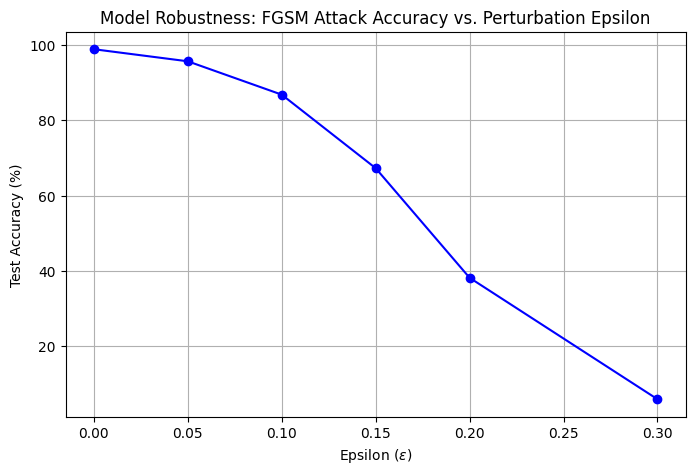

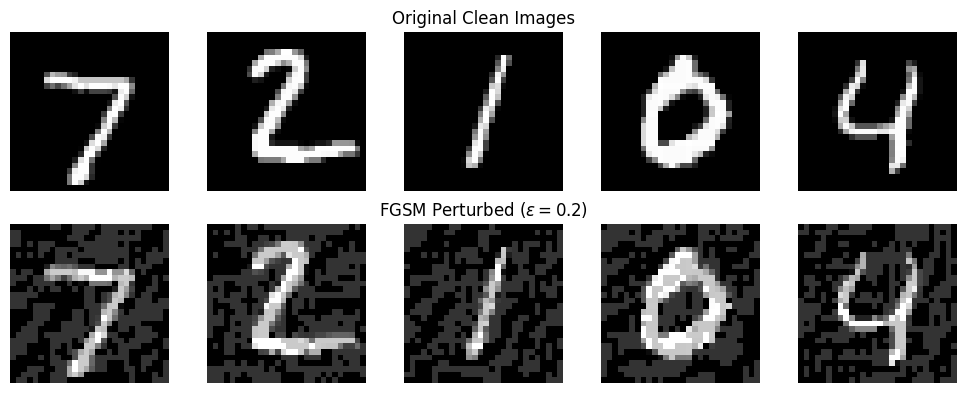

In [11]:
# Cell 7: Evaluate Accuracy Drop Across Epsilon & Plot Results (Warning-Free)
epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
fgsm_accuracies = []

for eps in epsilons:
  correct = 0
  total = 0
  for data, target in test_loader:
    data, target = data.to(device), target.to(device)
    if eps > 0:
      adv_data = generate_fgsm_attack(model, data, target, eps)
    else:
      adv_data = data
    output = model(adv_data)
    _, predicted = torch.max(output.data, 1)
    total += target.size(0)
    correct += (predicted == target).sum().item()

  acc = 100.0 * correct / total
  fgsm_accuracies.append(acc)
  print(f"Epsilon: {eps:.2f} \t FGSM Test Accuracy: {acc:.2f}%")

# Plotting Accuracy vs Epsilon (Using raw string r"..." to fix SyntaxWarning)
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, marker="o", color="b", linestyle="-")
plt.title(r"Model Robustness: FGSM Attack Accuracy vs. Perturbation Epsilon")
plt.xlabel(r"Epsilon ($\epsilon$)")
plt.ylabel("Test Accuracy (%)")
plt.grid(True)
plt.show()

# Visualize Side-by-Side Clean vs Perturbed Images
data_iter = iter(test_loader)
images, labels = next(data_iter)
images, labels = images.to(device), labels.to(device)
adv_images = generate_fgsm_attack(model, images, labels, epsilon=0.2)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(5):
  # Clean image
  axes[0, i].imshow(images[i].detach().cpu().squeeze(), cmap="gray")
  axes[0, i].axis("off")
  if i == 2:
    axes[0, i].set_title("Original Clean Images")

  # Perturbed image (Using raw string r"..." here as well)
  axes[1, i].imshow(adv_images[i].detach().cpu().squeeze(), cmap="gray")
  axes[1, i].axis("off")
  if i == 2:
    axes[1, i].set_title(r"FGSM Perturbed ($\epsilon=0.2$)")

plt.tight_layout()
plt.show()